# Netflix reviews – data cleaning

This notebook turns the raw Google Play reviews into three files:

| File | Content | Used for |
| --- | --- | --- |
| `netflix_reviews_ratings.csv` | every review from the chosen years | star ratings |
| `netflix_reviews_clean_full.csv` | every clean English review | text analysis |
| `netflix_reviews_to_annotate.csv` | clean English reviews with 3 or more words | annotation |

Every step follows the same pattern: **why** the step is needed, **look** at the data, **decide and apply**, then **check** what was removed.

## 0. Setup

In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import words
from fast_langdetect import detect

pd.set_option('display.max_colwidth', 120)

In [ ]:
FILE_PATH = './netflix_reviews.csv'
APP_NAME = 'netflix'
YEARS_TO_KEEP = [2022, 2023, 2026]

### Helpers
`log_step` records how many reviews are left after each step, overall and per year.
`show_removed` prints how many reviews a step removed and shows a random sample of them, so every cut can be checked by eye.

In [34]:
cleaning_log = []
year_log = []

def log_step(step_name, data):
    cleaning_log.append((step_name, len(data)))
    year_log.append(data['year'].value_counts().sort_index().rename(step_name))
    print(f"{step_name}: {len(data):,} reviews left")

def show_removed(before, after, n=10):
    removed = before[~before['reviewId'].isin(after['reviewId'])]
    print(f"Removed: {len(removed):,} reviews ({len(removed) / len(before) * 100:.1f}%)")
    if len(removed) > 0:
        return removed[['content', 'score', 'year']].sample(min(n, len(removed)), random_state=1)

## 1. First look at the raw data
**Why:** before cleaning, we need to know what the file contains: which columns, how many missing values, and which years the reviews cover.

In [35]:
df_raw = pd.read_csv(FILE_PATH)
print(df_raw.shape)
df_raw.head(3)

(1641518, 11)


,reviewId,userName,userImage,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,appVersion
0,02dbf18c-f991-40cb-a1d4-08c156c7966e,A Google user,https://play-lh.googleusercontent.com/EGemoI2NTXmTsBVtJqk8jxF9rh8ApRWfsIMQSt2uE4OcpQqbFu7f7NbTK05lx80nuSijCz7sc3a277...,amezing experience,5,0,9.83.0 build 6 74540,2026-09-28 06:53:32,NaN,NaN,9.83.0 build 6 74540
1,881d6cac-2f4b-4c0e-9f7c-55e7fa6cf28c,A Google user,https://play-lh.googleusercontent.com/EGemoI2NTXmTsBVtJqk8jxF9rh8ApRWfsIMQSt2uE4OcpQqbFu7f7NbTK05lx80nuSijCz7sc3a277...,你每晚饿车车,5,0,NaN,2026-09-28 06:51:47,NaN,NaN,NaN
2,86eeee0f-54e9-4d7b-88ce-040149ca4727,A Google user,https://play-lh.googleusercontent.com/EGemoI2NTXmTsBVtJqk8jxF9rh8ApRWfsIMQSt2uE4OcpQqbFu7f7NbTK05lx80nuSijCz7sc3a277...,i hate this app when I try signing in it leaves and comes bro no stars,1,0,NaN,2026-09-28 06:50:42,NaN,NaN,NaN


In [36]:
print(df_raw.isna().sum())

reviewId                      0
userName                      0
userImage                     0
content                    4981
score                         0
thumbsUpCount                 0
reviewCreatedVersion     442911
at                            0
replyContent            1641518
repliedAt               1641518
appVersion               442911
dtype: int64


In [37]:
df_raw['at'] = pd.to_datetime(df_raw['at'], errors='coerce')
df_raw['year'] = df_raw['at'].dt.year
print("First review:", df_raw['at'].min())
print("Last review: ", df_raw['at'].max())

First review: 2011-05-12 18:50:37
Last review:  2026-09-28 06:53:32


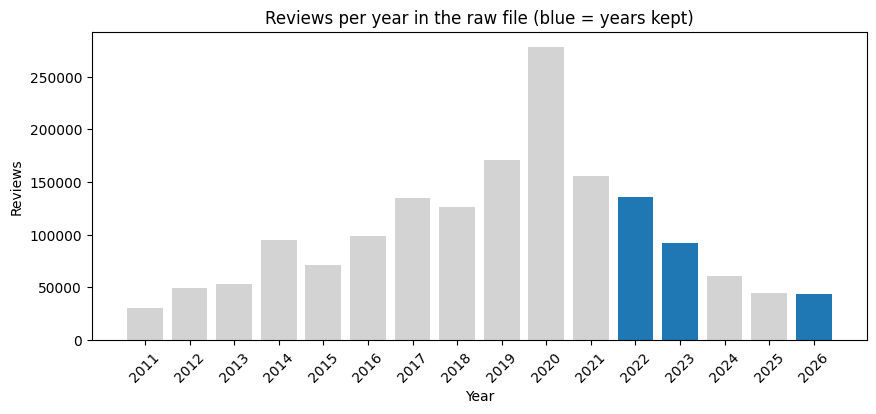

In [38]:
reviews_per_year = df_raw['year'].value_counts().sort_index()
bar_colors = ['tab:blue' if year in YEARS_TO_KEEP else 'lightgrey' for year in reviews_per_year.index]

plt.figure(figsize=(10, 4))
plt.bar(reviews_per_year.index.astype(str), reviews_per_year.values, color=bar_colors)
plt.title('Reviews per year in the raw file (blue = years kept)')
plt.xlabel('Year')
plt.ylabel('Reviews')
plt.xticks(rotation=45)
plt.show()

**What we see:** the file covers many years. The project compares a fixed set of years, so the next step keeps only those.
The last year in the file is not complete (see the last review date above), so for that year averages and shares can be compared, raw counts cannot.

## 2. Keep the project years → ratings set
**Why:** the research question compares the years set by the project. Reviews from other years are not part of the comparison.

We keep only the columns we need: the review id, text, star rating, likes and date. User names, profile pictures and app versions say nothing about consumer value, and user names are personal data we do not need.

In [39]:
df = df_raw[['reviewId', 'content', 'score', 'thumbsUpCount', 'at', 'year']].copy()
df['app'] = APP_NAME

print("Original file:", len(df_raw))
df = df[df['year'].isin(YEARS_TO_KEEP)].copy()
log_step('Years kept', df)

Original file: 1641518
Years kept: 272,382 reviews left


**Decision:** the ratings set is saved here, before any text filter.
A star rating is valid whatever the review text says or which language it is written in, so star ratings are always counted on all reviews from the chosen years.

In [40]:
df_ratings = df[['reviewId', 'app', 'year', 'score', 'thumbsUpCount', 'at']].copy()
df_ratings.to_csv(f'{APP_NAME}_reviews_ratings.csv', index=False)
print("Saved ratings set:", len(df_ratings))

Saved ratings set: 272382


In [41]:
ratings_per_year = df_ratings.groupby('year')['score'].agg(['count', 'mean']).round(2)
ratings_per_year.columns = ['reviews', 'average_stars']
ratings_per_year

,reviews,average_stars
year,,
2022,136210,3.71
2023,92247,2.88
2026,43925,3.55


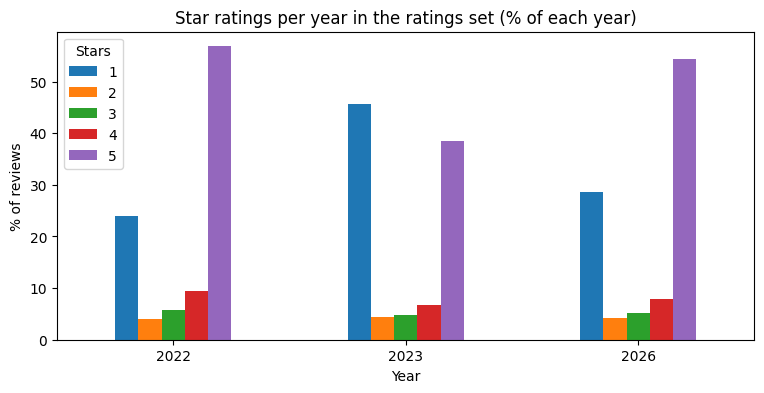

In [42]:
star_share_per_year = pd.crosstab(df_ratings['year'], df_ratings['score'], normalize='index').mul(100).round(1)
star_share_per_year.plot(kind='bar', figsize=(9, 4))
plt.title('Star ratings per year in the ratings set (% of each year)')
plt.xlabel('Year')
plt.ylabel('% of reviews')
plt.xticks(rotation=0)
plt.legend(title='Stars')
plt.show()

## 3. Remove reviews with no text
**Why:** a review without words cannot be read or annotated. Its star rating is already kept in the ratings set.

In [43]:
print("Reviews with no text:", df['content'].isna().sum())

Reviews with no text: 44


In [44]:
df_before = df.copy()
df = df.dropna(subset=['content'])
df['content'] = df['content'].astype(str)
log_step('No missing text', df)
show_removed(df_before, df)

No missing text: 272,338 reviews left
Removed: 44 reviews (0.0%)


,content,score,year
167274,NaN,3,2023
156684,NaN,1,2023
306240,NaN,5,2022
271224,NaN,1,2022
279485,NaN,5,2022
361846,NaN,5,2022
252656,NaN,5,2022
330606,NaN,5,2022
327628,NaN,4,2022
321139,NaN,5,2022


## 4. Clean the text
**Why:** to count words and check the language, the text must be in one simple form.
We work on a copy (`content_clean`). The original `content` stays untouched, so the annotator always reads what the user really wrote.
Each sub-step below shows how many reviews it changes and some examples before and after.

### 4a. Lowercase and straight apostrophes
**Why:** "Great" and "great" should count as the same word. Phones often type curly apostrophes (’), which would make "don’t" and "don't" different words.
Apostrophes are kept, because they change the meaning ("can't" is not "can").

In [45]:
has_curly = df['content'].str.contains('[’‘]', regex=True)
print(f"Reviews with curly apostrophes: {has_curly.sum():,} ({has_curly.mean() * 100:.1f}%)")

df['content_clean'] = df['content'].str.lower()
df['content_clean'] = df['content_clean'].str.replace('’', "'").str.replace('‘', "'")

df.loc[has_curly, ['content', 'content_clean']].head(5)

Reviews with curly apostrophes: 382 (0.1%)


,content,content_clean
120,"1 star just for notice... (rate 5 star afterwards) 1.please add ""previous"" button while watching series just beside ...","1 star just for notice... (rate 5 star afterwards) 1.please add ""previous"" button while watching series just beside ..."
160,"If I had to name one of the best movies I’ve watched this year, this would definitely be one of my top choices. Most...","if i had to name one of the best movies i've watched this year, this would definitely be one of my top choices. most..."
253,Netflix keeps showing shows I’ve already watched. There should be an option to filter out watched content so it’s ea...,netflix keeps showing shows i've already watched. there should be an option to filter out watched content so it's ea...
356,Getting more expensive!! Not worth it anymore..I’m out..Unsubscribing..huh,getting more expensive!! not worth it anymore..i'm out..unsubscribing..huh
363,I really really enjoy using Netflix because there are so many great films to explore. I’m always finding something n...,i really really enjoy using netflix because there are so many great films to explore. i'm always finding something n...


### 4b. Remove emojis, symbols and punctuation
**Why:** word counts and the dictionary check work on words only. Emojis, symbols and punctuation are replaced by a space, so words that were glued to them stay separate.
Apostrophes inside words are kept; stray quote marks around words are removed.

In [46]:
has_symbols = df['content_clean'].str.contains(r"[^a-z0-9\s']", regex=True)
print(f"Reviews with emojis, symbols or punctuation: {has_symbols.sum():,} ({has_symbols.mean() * 100:.1f}%)")

# most common characters that will be removed
removed_characters = df['content_clean'].str.findall(r"[^a-z0-9\s']").explode().dropna()
removed_characters.value_counts().head(20)

Reviews with emojis, symbols or punctuation: 118,511 (43.5%)


content_clean
.    183889
,     62214
!     45880
?     14655
ا     11526
👍      8205
️      8148
ل      7980
"      7062
ي      6428
-      6388
❤      6262
م      4829
و      4559
ر      4216
)      4121
/      3915
(      3913
👎      3866
ت      3779
Name: count, dtype: int64

In [47]:
df['content_clean'] = df['content_clean'].str.replace(r"[^a-z0-9\s']+", ' ', regex=True)
df['content_clean'] = df['content_clean'].str.replace(r"(?<![a-z0-9])'+|'+(?![a-z0-9])", ' ', regex=True)

df.loc[has_symbols, ['content', 'content_clean']].sample(min(10, has_symbols.sum()), random_state=1)

,content,content_clean
342784,Why do yall keep taking good movies off and adding stupid ones. My son watches the kung fu panda and despicable mes ...,why do yall keep taking good movies off and adding stupid ones my son watches the kung fu panda and despicable mes ...
287855,Good movies to watch...,good movies to watch
330229,ATLEAST HULU KEEPS ITS PRICES THE SAME...WITH NO SCREEN LIMIT...NETFLIX WANTS $20 JUST TO WATCH ON 2 SCREENS... REDI...,atleast hulu keeps its prices the same with no screen limit netflix wants 20 just to watch on 2 screens rediculous...
244546,"Xiaomi 11T, HDR content color yellowish. However HD no problem",xiaomi 11t hdr content color yellowish however hd no problem
213429,Egypt for Egyptians😘,egypt for egyptians
251498,Netflix used to be good. You used to be able to click genre of movie and up would come a list of movies. Now its a l...,netflix used to be good you used to be able to click genre of movie and up would come a list of movies now its a l...
309256,Haven't had an experience Yet!,haven't had an experience yet
287392,Your Umbrella Academy want to writing Allah's (god) name on the floor? Please do respect on our religion. Hope you c...,your umbrella academy want to writing allah's god name on the floor please do respect on our religion hope you c...
278052,You guys really need to make English dubbing available for shows and movies with multiple languages. I struggle with...,you guys really need to make english dubbing available for shows and movies with multiple languages i struggle with...
295432,"so i love this app but i think u should add more anime like ""maid sama"" i love that and add ""kiss him not me"" if u d...",so i love this app but i think u should add more anime like maid sama i love that and add kiss him not me if u d...


### 4c. Remove words that contain numbers
**Why:** tokens like "4k", "v2" or "2023" are versions, prices or dates, not words. If kept, they would make a review look longer, and less English, than it is.

In [48]:
number_tokens = df['content_clean'].str.findall(r"\S*\d\S*").explode().dropna()
has_numbers = df['content_clean'].str.contains(r"\d", regex=True)
print(f"Reviews with a number token: {has_numbers.sum():,} ({has_numbers.mean() * 100:.1f}%)")
print("Most common number tokens:")
number_tokens.value_counts().head(20)

Reviews with a number token: 22,549 (8.3%)
Most common number tokens:


content_clean
2       3768
5       3426
1       3058
3       2218
10      1943
4       1769
7        862
6        778
8        708
0        656
99       579
20       556
9        526
4k       512
100      450
15       410
30       397
12       302
11       263
2022     262
Name: count, dtype: int64

In [49]:
df['content_clean'] = df['content_clean'].str.replace(r"\S*\d\S*", ' ', regex=True)
df['content_clean'] = df['content_clean'].str.replace(r'\s+', ' ', regex=True).str.strip()

df.loc[has_numbers, ['content', 'content_clean']].sample(min(10, has_numbers.sum()), random_state=1)

,content,content_clean
253649,Need to go back to the old design. I would suggest you ask you customers what they need in a design. The current one...,need to go back to the old design i would suggest you ask you customers what they need in a design the current one g...
226854,"If you switch away from a show to check the time, it won't resume from last point reached, you have to find the epis...",if you switch away from a show to check the time it won't resume from last point reached you have to find the episod...
368585,"Good but on Google it said ""this season is coming out on 21st January 2022"" but never came out on netflix 😡😤",good but on google it said this season is coming out on january but never came out on netflix
350065,I liked Netflix but the worst part is everything I actually watch is slowly being removed and the app works when it ...,i liked netflix but the worst part is everything i actually watch is slowly being removed and the app works when it ...
277836,5 star not enough for Netflix 🥵,star not enough for netflix
293023,The word can't have meaning to describe this creation and we get all the best movies and Animes within a sec. But th...,the word can't have meaning to describe this creation and we get all the best movies and animes within a sec but the...
316366,Netflix was good but Now we can't watch it on more than one screen so me and my family have to take turns watching o...,netflix was good but now we can't watch it on more than one screen so me and my family have to take turns watching o...
223754,Since the update my Netflix will not play on my tv. It will at for about 10 to 20 seconds then kicks off. It needs t...,since the update my netflix will not play on my tv it will at for about to seconds then kicks off it needs to be fixed
3720,why does my payment only lasts for 3 weeks only? while I pay for a monthly?,why does my payment only lasts for weeks only while i pay for a monthly
306451,World's number 1 app Netflix next review movie salaar,world's number app netflix next review movie salaar


### 4d. Remove reviews with no real word left
**Why:** after cleaning, some reviews are empty or only single letters (they were only emojis, numbers or symbols). They have nothing to read or annotate.
A review must contain at least one word of two or more letters.

In [50]:
df_before = df.copy()
df = df[df['content_clean'].str.contains(r'[a-z]{2,}', regex=True)].copy()
log_step('Has a real word', df)
show_removed(df_before, df)

Has a real word: 263,111 reviews left
Removed: 9,227 reviews (3.4%)


,content,score,year
365248,مشجع و محرض على الإنحلال الأخلاقي و التفكك الأسري ، بالإضافة لشغف صناع المحتوى لترسيخ الشذوذ الجنسي.,1,2022
160833,عدو للإسلام و الإنسانية ببساطة لأنه صناعة أمريكية صهيونية,1,2023
175553,😍😍😍😍😍😍😍😍😍😍😍😍😍😍,5,2023
338730,😍😍😍😍,5,2022
367028,البرنامج ده حاجه تقرف ومقتنعين ان احنا ك عرب هنحب الخرا القذر دا,1,2022
336880,👌👌👌👌,3,2022
313279,👍 👌,5,2022
306247,👎👎👎👎,1,2022
40186,💦💗,5,2026
257866,👍💫💫💫🕺💃🎶🎶🕺💃🎶🕺,5,2022


## 5. Keep English reviews
**Why:** the annotation and the word checks are in English. Two checks are used:
- **5a. Language detector:** removes reviews written in another language.
- **5b. Dictionary check:** removes gibberish and other-language text the detector missed.

### 5a. Language detector
The language is detected on the **original** text, because punctuation and full sentences help the detector.

In [51]:
def detect_language(text):
    try:
        result = detect(text.replace('\n', ' '), model='auto', k=1)
        return result[0]['lang']
    except Exception:
        return 'unknown'

df['language'] = df['content'].apply(detect_language)
language_counts = df['language'].value_counts()
print(f"Detected as English: {(df['language'] == 'en').sum():,} ({(df['language'] == 'en').mean() * 100:.1f}%)")
language_counts.head(15)

Detected as English: 244,211 (92.8%)


language
en     244211
it       2328
de       2296
fr       1956
es       1894
nl       1060
pt        891
id        864
ru        627
sv        617
pl        488
ceb       401
tl        394
ja        386
hu        385
Name: count, dtype: int64

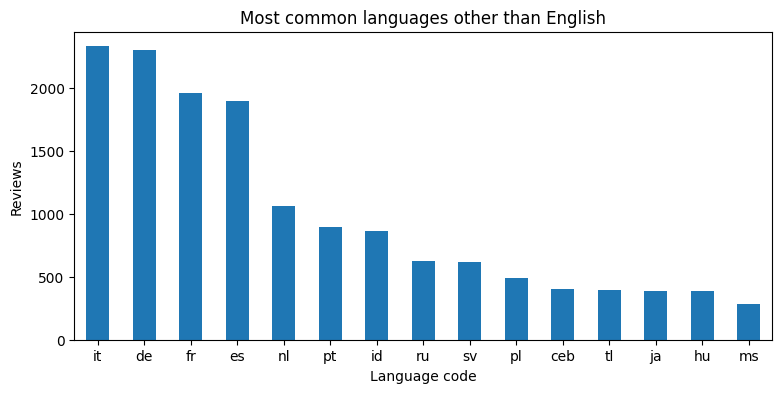

In [52]:
plt.figure(figsize=(9, 4))
language_counts.drop('en', errors='ignore').head(15).plot(kind='bar')
plt.title('Most common languages other than English')
plt.xlabel('Language code')
plt.ylabel('Reviews')
plt.xticks(rotation=0)
plt.show()

In [54]:
# examples of reviews detected as another language
not_english = df[df['language'] != 'en']
not_english[['content', 'language']].sample(min(15, len(not_english)))

,content,language
327278,Ok,it
296235,All out hackers,es
191252,2¥aa,fi
4547,Wow I love Netflix💋💋💋💋💖💖💖💋💖💖💋💖💖💖🎉🎉,hu
311319,Yeah,ja
281990,Nul,ro
275089,Very,uk
246359,Sogib,de
176672,Ki oo okk ko o,cy
348949,Gud,sv


In [23]:
df_before = df.copy()
df = df[df['language'] == 'en'].copy()
log_step('English (detector)', df)
show_removed(df_before, df)

English (detector): 244,211 reviews left
Removed: 18,900 reviews (7.2%)


,content,score,year
359265,Great...,5,2022
317750,Sürekli hata veriyor. Uygulama telefonda açılmıyor,1,2022
349325,Woah,5,2022
167430,Nice 🙂,5,2023
214793,Bad,1,2023
200394,Waste,1,2023
292460,OSM,5,2022
299364,Sex,2,2022
331176,vesx,4,2022
171255,Ok,5,2023


### 5b. Dictionary check
**Why:** some reviews pass the detector but are not readable English: gibberish ("eww ee ww"), names, or other languages written in Latin letters.
For each review we compute the share of its words that are English words. A review is kept if at least `MIN_REAL_WORD_RATIO` of its words are real words.

**A strict dictionary is not enough.** The NLTK word list misses many normal forms ("crashing", "discontinued") and app words ("netflix", "subscription"). So a word also counts as real if:
- it contains an apostrophe (contractions like "don't", "it's");
- it is an app or streaming word from our list;
- it is a dictionary word plus a common ending (-s, -es, -d, -ed, -ing, -ly, -er), also with a doubled letter ("stopped" → "stop").

In [55]:
nltk.download('words', quiet=True)
english_vocab = set(w.lower() for w in words.words())
app_words = {'netflix', 'amazon', 'prime', 'app', 'apps', 'tv', 'ok', 'okay', 'ads', 'advert', 'adverts', 'advt',
             'subscription', 'subscriptions', 'streaming', 'login', 'logout', 'wifi', 'roku', 'firestick',
             'chromecast', 'android', 'iphone', 'ipad', 'ott', 'hd', 'overpriced', 'cancelled', 'canceled'}
english_vocab = english_vocab | app_words

def is_dictionary_word(word):
    return word in english_vocab

def is_real_word(word):
    if "'" in word or word in english_vocab:
        return True
    for ending in ['s', 'es', 'd', 'ed', 'ing', 'ly', 'er']:
        if word.endswith(ending):
            base = word[:-len(ending)]
            if len(base) >= 3 and (base in english_vocab or base[:-1] in english_vocab):
                return True
    return False

def real_word_ratio(text, word_check):
    tokens = text.split()
    return sum(1 for w in tokens if word_check(w)) / len(tokens)

df['strict_ratio'] = df['content_clean'].apply(lambda text: real_word_ratio(text, is_dictionary_word))
df['real_word_ratio'] = df['content_clean'].apply(lambda text: real_word_ratio(text, is_real_word))
df['real_word_ratio'].describe()

count    263111.000000
mean          0.921455
std           0.199900
min           0.000000
25%           0.950000
50%           1.000000
75%           1.000000
max           1.000000
Name: real_word_ratio, dtype: float64

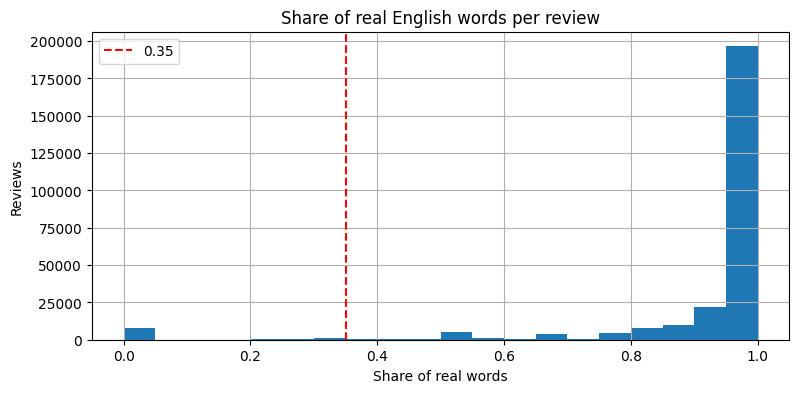

In [56]:
plt.figure(figsize=(9, 4))
df['real_word_ratio'].hist(bins=20)
plt.axvline(0.35, color='red', linestyle='--', label='0.35')
plt.title('Share of real English words per review')
plt.xlabel('Share of real words')
plt.ylabel('Reviews')
plt.legend()
plt.show()

**Choosing the threshold:** compare how many reviews each threshold removes, and read examples in each band.

In [57]:
for threshold in [0.25, 0.35, 0.5]:
    removed = (df['real_word_ratio'] < threshold).sum()
    print(f"Threshold {threshold}: removes {removed:,} reviews ({removed / len(df) * 100:.1f}%)")

Threshold 0.25: removes 8,168 reviews (3.1%)
Threshold 0.35: removes 9,694 reviews (3.7%)
Threshold 0.5: removes 10,976 reviews (4.2%)


In [58]:
bands = [(0, 0.25), (0.25, 0.35), (0.35, 0.5)]
for low, high in bands:
    band = df[(df['real_word_ratio'] >= low) & (df['real_word_ratio'] < high)]
    print(f"--- share of real words {low}–{high}: {len(band):,} reviews ---")
    print(band['content'].sample(min(10, len(band)), random_state=1).to_string(index=False))
    print()

--- share of real words 0–0.25: 8,168 reviews ---
                                                                                        Describeyourexperience optionall
                                                                                                     Tumchya aicha pucha
                                                                                                                     Sei
                                                                                                                     Nic
                                                                                                                    Ehhh
                                                                                                                     nic
                                                                                                           Aproveeeee!!!
                                                                                                       

**Strict vs loosened dictionary:** these reviews would be removed with the strict word list but are kept with the loosened one.

In [59]:
brought_back = df[(df['strict_ratio'] < 0.35) & (df['real_word_ratio'] >= 0.35)]
print("Reviews kept thanks to the loosened dictionary:", len(brought_back))
brought_back[['content', 'content_clean']].sample(min(15, len(brought_back)), random_state=1)

Reviews kept thanks to the loosened dictionary: 2463


,content,content_clean
161747,Goodd,goodd
312767,Movies,movies
37216,It's soo perfect,it's soo perfect
158567,"Bagus dan film seru"" nya bnyak",bagus dan film seru nya bnyak
19937,Baised reality shows,baised reality shows
192837,Better tenn movies!,better tenn movies
345206,Deez nuts,deez nuts
230345,Robis,robis
217118,liars,liars
324831,"Hay muchas series nuevas coreanas que quiero ver pero nonestan en español ,Netflix me estas perdiendo",hay muchas series nuevas coreanas que quiero ver pero nonestan en espa ol netflix me estas perdiendo


In [60]:
MIN_REAL_WORD_RATIO = 0.35

df_before = df.copy()
df = df[df['real_word_ratio'] >= MIN_REAL_WORD_RATIO].copy()
df = df.drop(columns=['strict_ratio', 'real_word_ratio', 'language'])
log_step('Real English words', df)
show_removed(df_before, df, n=20)

Real English words: 253,417 reviews left
Removed: 9,694 reviews (3.7%)


,content,score,year
23061,verry verry bad apk🤮🤮🤮,1,2026
300751,Bestttt,5,2022
259807,Faadu ekdum,5,2022
349717,Wakeelkhan,5,2022
196661,Falatu,1,2023
356619,Guuuuuu,1,2022
311057,Mikki avd m ii o k Ki i umkll ki kisi ki,3,2022
8654,yay,5,2026
179411,Niceee,5,2023
195415,Showmax 100,4,2023


## 6. Save the full clean set
This set keeps every clean English review. It is used for the text analysis, so it is not reduced any further.

In [61]:
df['word_count'] = df['content_clean'].str.split().str.len()
df_clean_full = df.copy()
df_clean_full.to_csv(f'{APP_NAME}_reviews_clean_full.csv', index=False)
print("Saved full clean set:", len(df_clean_full))

Saved full clean set: 253417


**Check: does the text cleaning change the star ratings?** If the averages per year are close, removing empty, non-English and gibberish reviews does not bias the ratings.

In [62]:
rating_check = pd.DataFrame({
    'ratings_set': df_ratings.groupby('year')['score'].mean(),
    'clean_text_set': df_clean_full.groupby('year')['score'].mean()}).round(2)
rating_check['difference'] = rating_check['clean_text_set'] - rating_check['ratings_set']
rating_check

,ratings_set,clean_text_set,difference
year,,,
2022,3.71,3.70,-0.01
2023,2.88,2.88,0.00
2026,3.55,3.53,-0.02


## 7. Review length → annotation set
**Why:** the annotation looks for the *reasons* behind satisfaction (price, ads, content, technical problems). The star rating already tells us *how* satisfied a user is.
Very short reviews ("good", "love it") show a feeling but rarely a reason. We look at the data to decide how many words a review needs.

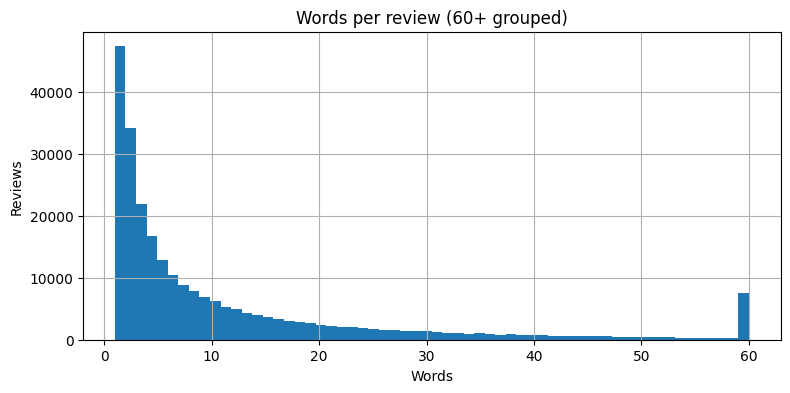

In [63]:
plt.figure(figsize=(9, 4))
df_clean_full['word_count'].clip(upper=60).hist(bins=60)
plt.title('Words per review (60+ grouped)')
plt.xlabel('Words')
plt.ylabel('Reviews')
plt.show()

In [64]:
df_clean_full['words_group'] = df_clean_full['word_count'].clip(upper=11)
group_labels = {i: str(i) for i in range(1, 11)}
group_labels[11] = '11+'

length_table = df_clean_full.groupby('words_group').agg(
    reviews=('reviewId', 'count'),
    average_stars=('score', 'mean'))
length_table['% of reviews'] = (length_table['reviews'] / len(df_clean_full) * 100).round(1)
length_table['average_stars'] = length_table['average_stars'].round(2)
length_table.index = length_table.index.map(group_labels)
length_table

,reviews,average_stars,% of reviews
words_group,,,
1,47415,4.46,18.7
2,34214,4.01,13.5
3,21924,3.54,8.7
4,16744,3.50,6.6
5,12900,3.32,5.1
6,10426,3.23,4.1
7,8892,3.15,3.5
8,7818,3.16,3.1
9,6970,3.12,2.8


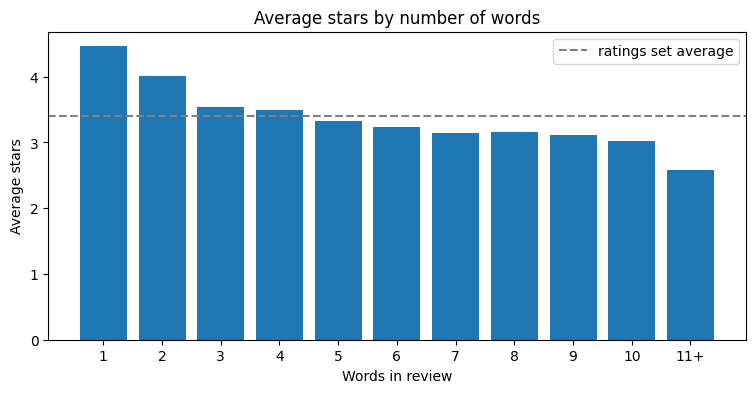

In [65]:
plt.figure(figsize=(9, 4))
plt.bar(length_table.index, length_table['average_stars'])
plt.axhline(df_ratings['score'].mean(), color='grey', linestyle='--', label='ratings set average')
plt.title('Average stars by number of words')
plt.xlabel('Words in review')
plt.ylabel('Average stars')
plt.legend()
plt.show()

**Do short reviews talk about value?** We count reviews that mention a price, ads or subscription word, by length.

In [66]:
value_words = (r"\b(price|prices|expensive|cheap|money|cost|costs|pay|paid|paying|worth|subscription|"
               r"rent|rental|ads|ad|advt|advertisement|advertisements|free|fee|charge|charged|membership)\b")
df_clean_full['mentions_value'] = df_clean_full['content_clean'].str.contains(value_words, regex=True)

value_table = df_clean_full.groupby('words_group')['mentions_value'].agg(['mean', 'sum'])
value_table.columns = ['% mentioning value', 'reviews mentioning value']
value_table['% mentioning value'] = (value_table['% mentioning value'] * 100).round(1)
value_table.index = value_table.index.map(group_labels)
value_table

C:\Users\elesa\AppData\Local\Temp\ipykernel_9228\2328727743.py:3: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_clean_full['mentions_value'] = df_clean_full['content_clean'].str.contains(value_words, regex=True)


,% mentioning value,reviews mentioning value
words_group,,
1,0.3,122
2,1.4,479
3,2.2,491
4,3.6,608
5,4.7,601
6,5.9,620
7,6.8,601
8,7.6,592
9,8.3,577


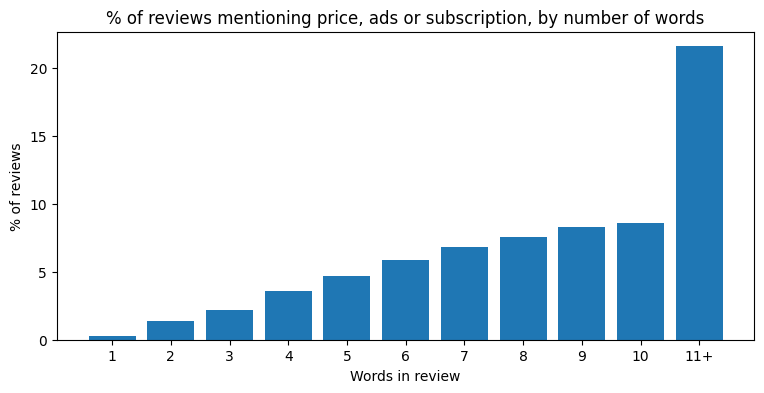

In [67]:
plt.figure(figsize=(9, 4))
plt.bar(value_table.index, value_table['% mentioning value'])
plt.title('% of reviews mentioning price, ads or subscription, by number of words')
plt.xlabel('Words in review')
plt.ylabel('% of reviews')
plt.show()

**Reading examples:** do reviews of this length give a reason?

In [68]:
for n_words in [1, 2, 3, 4, 5]:
    print(f"--- {n_words} words ---")
    same_length = df_clean_full[df_clean_full['word_count'] == n_words]['content']
    examples = same_length.sample(min(15, len(same_length)), random_state=1)
    print(examples.to_string(index=False))
    print()

--- 1 words ---
        Nice
        Good
         Wow
   Wonderful
        Nice
        Cool
         Oki
       Worst
      👍great
   Enjoyable
     good 👍🏻
        Nice
         Bad
       great
professional

--- 2 words ---
                AA T@1
              Best app
             Great app
    Best entertainment
        Nyc,,, love❤❤❤
           Good moives
             Worst app
           besttt ever
         Enjoy Netflix
    My favorite ❣️❣️❣️
            It's cool.
            great apps
Decrease 4screen price
              Fuxk you
              The best

--- 3 words ---
          not so good
            I love it
    Great and amazing
          I'm on good
    Loading very slow
 2 words Fuller House
      simply the best
     Not enough movie
   app not responding
   Biased show makers
Too expensive plans !
 No 1 Netflix 1B Like
       Very Very good
       LOVE THIS SHOW
    Not enough movies

--- 4 words ---
                  This app is awesome.
                       G

**Comparing cuts:** what each minimum length keeps, and how it changes the stars and the years.

In [69]:
cut_rows = []
for min_words in [1, 2, 3, 4, 5]:
    kept = df_clean_full[df_clean_full['word_count'] >= min_words]
    row = {'minimum words': min_words,
           'reviews kept': len(kept),
           '% kept': round(len(kept) / len(df_clean_full) * 100, 1),
           'average stars': round(kept['score'].mean(), 2),
           '% 5 stars': round((kept['score'] == 5).mean() * 100, 1)}
    for year in YEARS_TO_KEEP:
        year_total = (df_clean_full['year'] == year).sum()
        row[f'% of {year} kept'] = round((kept['year'] == year).sum() / year_total * 100, 1)
    cut_rows.append(row)

cut_table = pd.DataFrame(cut_rows)
cut_table

,minimum words,reviews kept,% kept,average stars,% 5 stars,% of 2022 kept,% of 2023 kept,% of 2026 kept
0,1,253417,100.0,3.40,49.8,100.0,100.0,100.0
1,2,206002,81.3,3.15,43.3,78.1,84.3,84.9
2,3,171788,67.8,2.98,38.4,63.5,71.6,73.0
3,4,149864,59.1,2.90,35.7,55.2,61.8,65.5
4,5,133120,52.5,2.82,33.4,48.6,55.0,59.3


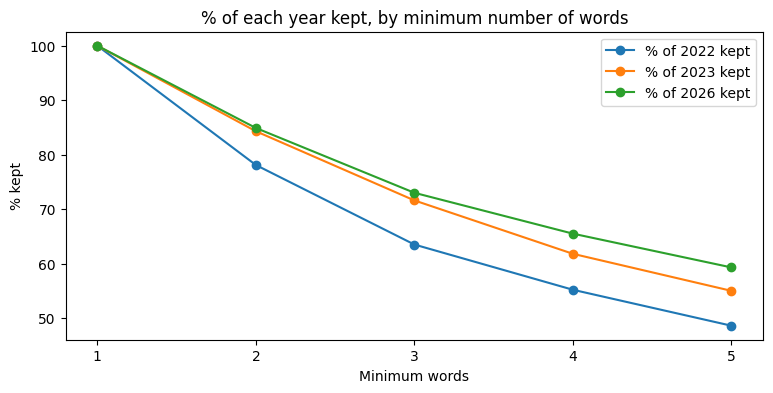

In [70]:
year_columns = [f'% of {year} kept' for year in YEARS_TO_KEEP]
cut_table.set_index('minimum words')[year_columns].plot(marker='o', figsize=(9, 4))
plt.title('% of each year kept, by minimum number of words')
plt.xlabel('Minimum words')
plt.ylabel('% kept')
plt.xticks(cut_table['minimum words'])
plt.show()

**Decision: 3 words or more.**
- 1–2 word reviews are almost only general praise and rarely give a reason.
- From 3 words, reviews start to give reasons, including short value complaints ("too many ads"). A 4-word minimum would lose these.
- Any minimum length makes the set more negative and more recent, because longer reviews are more often complaints and recent reviews are longer. This cannot be avoided if we want reasons, which is why star ratings are always taken from the ratings set.

In [71]:
MIN_WORDS = 3

df_before = df_clean_full.copy()
df_annotate = df_clean_full[df_clean_full['word_count'] >= MIN_WORDS].copy()
log_step(f'{MIN_WORDS}+ words', df_annotate)
show_removed(df_before, df_annotate, n=20)

3+ words: 171,788 reviews left
Removed: 81,629 reviews (32.2%)


,content,score,year
374060,Nice,5,2022
27113,Good,5,2026
222368,Love it,5,2023
206140,Çox pis,1,2023
320837,Good,5,2022
172115,Very good 😊😊,5,2023
154920,Hey sn,3,2023
246112,So interesting,5,2022
26392,MJ ❤️ Documentary 👎,1,2026
297020,Good,5,2022


## 8. Why likes are not used to select reviews
**Why check:** likes could be a signal that a review is useful. Here we test whether a likes rule would improve the selection. Nothing is removed in this section.

In [72]:
has_like = df_clean_full['thumbsUpCount'] >= 1
like_table = pd.crosstab(df_clean_full['year'], df_clean_full['score'], values=has_like, aggfunc='mean').mul(100).round(1)
like_table

score,1,2,3,4,5
year,,,,,
2022,21.1,25.0,16.6,10.4,5.2
2023,22.8,31.1,19.9,12.1,6.6
2026,51.2,43.4,24.5,17.0,11.0


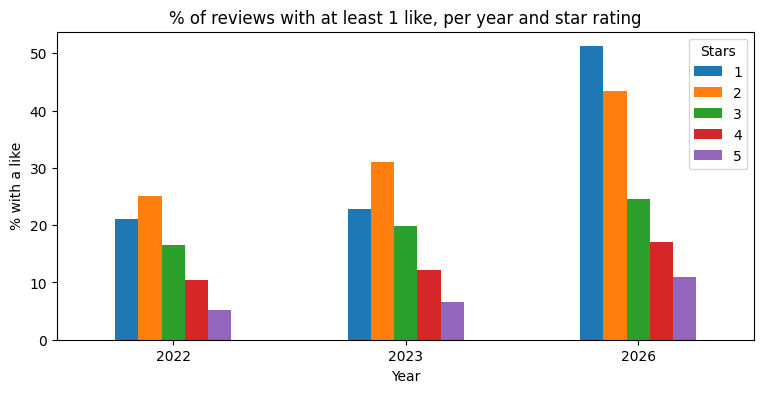

In [73]:
like_table.plot(kind='bar', figsize=(9, 4))
plt.title('% of reviews with at least 1 like, per year and star rating')
plt.xlabel('Year')
plt.ylabel('% with a like')
plt.xticks(rotation=0)
plt.legend(title='Stars')
plt.show()

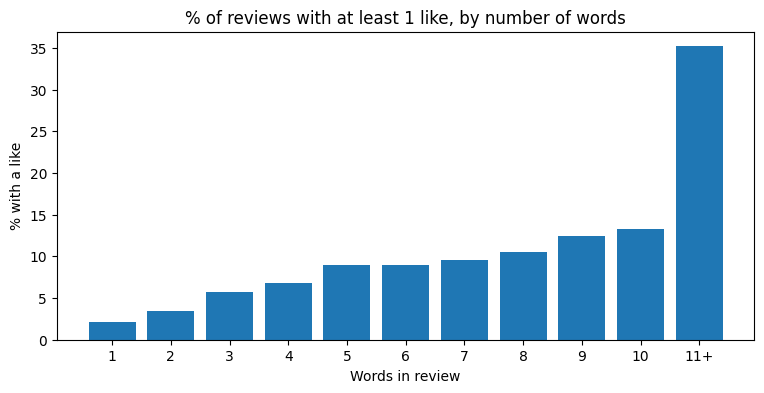

In [74]:
like_by_length = has_like.groupby(df_clean_full['words_group']).mean().mul(100).round(1)
like_by_length.index = like_by_length.index.map(group_labels)

plt.figure(figsize=(9, 4))
plt.bar(like_by_length.index, like_by_length.values)
plt.title('% of reviews with at least 1 like, by number of words')
plt.xlabel('Words in review')
plt.ylabel('% with a like')
plt.show()

**Testing a likes rule:** keep a review if it has enough words **or** enough likes. Long reviews already pass the words test, so the likes can only add short reviews.

In [75]:
like_rows = []
words_mask = df_clean_full['word_count'] >= MIN_WORDS
for min_likes in [1, 2, 5, 10]:
    likes_mask = df_clean_full['thumbsUpCount'] >= min_likes
    kept = df_clean_full[words_mask | likes_mask]
    like_rows.append({'rule': f'{MIN_WORDS}+ words or {min_likes}+ likes',
                      'reviews kept': len(kept),
                      'short reviews added by likes': (~words_mask & likes_mask).sum(),
                      'average stars': round(kept['score'].mean(), 2)})
for min_likes in [1, 5]:
    kept = df_clean_full[df_clean_full['thumbsUpCount'] >= min_likes]
    like_rows.append({'rule': f'{min_likes}+ likes only',
                      'reviews kept': len(kept),
                      'short reviews added by likes': None,
                      'average stars': round(kept['score'].mean(), 2)})

print(f"{MIN_WORDS}+ words alone: {words_mask.sum():,} reviews, average stars {df_annotate['score'].mean():.2f}")
pd.DataFrame(like_rows)

3+ words alone: 171,788 reviews, average stars 2.98


,rule,reviews kept,short reviews added by likes,average stars
0,3+ words or 1+ likes,174012,2224.0,2.98
1,3+ words or 2+ likes,172041,253.0,2.98
2,3+ words or 5+ likes,171829,41.0,2.98
3,3+ words or 10+ likes,171813,25.0,2.98
4,1+ likes only,38188,NaN,2.29
5,5+ likes only,7602,NaN,2.32


**Decision: no likes rule.**
- Adding likes rescues only a few short reviews and barely changes the selection.
- Likes go more often to negative reviews and depend on the year, so they are not a neutral signal of a useful review.
- Selecting on likes alone keeps few reviews and is strongly skewed.

## 9. Repeated texts
**Why check:** many identical reviews could be spam or a coordinated campaign rather than individual opinions.
Common short phrases ("i love this app") repeat naturally. A campaign looks like one specific message, often off-topic, many times, with all 1 or all 5 stars.

**Decision:** repeated texts are kept, because they are real reviews. The column `text_repeats` (how many times the same clean text appears) is added, so they can be identified or excluded later in the analysis.

In [76]:
df_annotate['text_repeats'] = df_annotate.groupby('content_clean')['reviewId'].transform('count')

repeated = (df_annotate[df_annotate['text_repeats'] >= 5]
            .groupby('content_clean')
            .agg(times=('reviewId', 'count'), average_stars=('score', 'mean'),
                 first_year=('year', 'min'), last_year=('year', 'max'))
            .sort_values('times', ascending=False))
repeated['average_stars'] = repeated['average_stars'].round(2)
print("Texts repeated 5 or more times:", len(repeated))
print("Reviews involved:", repeated['times'].sum())
repeated.head(25)

Texts repeated 5 or more times: 741
Reviews involved: 14863


,times,average_stars,first_year,last_year
content_clean,,,,
i love it,1149,4.79,2022,2026
egypt for egyptians,762,1.00,2023,2023
i love netflix,644,4.83,2022,2026
egypt for egyptian,626,1.01,2023,2023
i love this app,459,4.73,2022,2026
i like it,370,4.64,2022,2026
best app ever,330,4.85,2022,2026
very good app,297,4.76,2022,2026
love this app,236,4.79,2022,2026


## 10. Save the annotation set

In [77]:
annotate_cols = ['reviewId', 'app', 'year', 'score', 'thumbsUpCount', 'word_count', 'text_repeats', 'content', 'content_clean']
df_annotate[annotate_cols].to_csv(f'{APP_NAME}_reviews_to_annotate.csv', index=False)
print("Saved annotation set:", len(df_annotate))

Saved annotation set: 171788


## 11. Summary
### Reviews left after each step

In [78]:
log = pd.DataFrame(cleaning_log, columns=['step', 'rows_left'])
log['removed'] = log['rows_left'].shift(1) - log['rows_left']
log['removed_%_of_previous'] = (log['removed'] / log['rows_left'].shift(1) * 100).round(1)
print("Original file:", len(df_raw))
print(log.to_string(index=False))

Original file: 1641518
              step  rows_left  removed  removed_%_of_previous
        Years kept     272382      NaN                    NaN
   No missing text     272338     44.0                    0.0
   Has a real word     263111   9227.0                    3.4
Real English words     253417   9694.0                    3.7
          3+ words     171788  81629.0                   32.2


In [79]:
year_table = pd.concat(year_log, axis=1)
year_table

,Years kept,No missing text,Has a real word,Real English words,3+ words
year,,,,,
2022,136210,136183,131775,126305,80203
2023,92247,92231,88314,85172,60951
2026,43925,43924,43022,41940,30634


In [80]:
# % of each year's reviews still left after each step
year_pct = (year_table.div(year_table['Years kept'], axis=0) * 100).round(1)
year_pct

,Years kept,No missing text,Has a real word,Real English words,3+ words
year,,,,,
2022,100.0,100.0,96.7,92.7,58.9
2023,100.0,100.0,95.7,92.3,66.1
2026,100.0,100.0,97.9,95.5,69.7


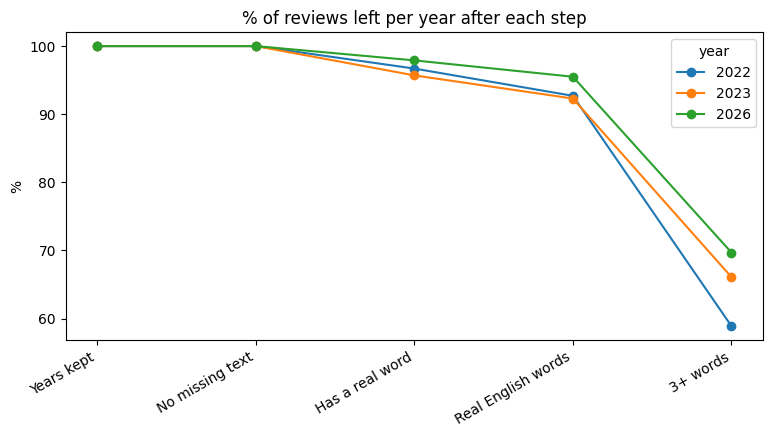

In [81]:
year_pct.T.plot(marker='o', figsize=(9, 4))
plt.title('% of reviews left per year after each step')
plt.ylabel('%')
plt.xticks(range(len(year_pct.columns)), year_pct.columns, rotation=30, ha='right')
plt.show()

### Star ratings in the three sets
The ratings set and the clean text set should be close. The annotation set is expected to be more negative, because it keeps longer reviews.

In [82]:
mean_rating_all = pd.DataFrame({
    'ratings_set': df_ratings.groupby('year')['score'].mean(),
    'clean_text_set': df_clean_full.groupby('year')['score'].mean(),
    'annotation_set': df_annotate.groupby('year')['score'].mean()}).round(2)
mean_rating_all

,ratings_set,clean_text_set,annotation_set
year,,,
2022,3.71,3.70,3.28
2023,2.88,2.88,2.48
2026,3.55,3.53,3.19


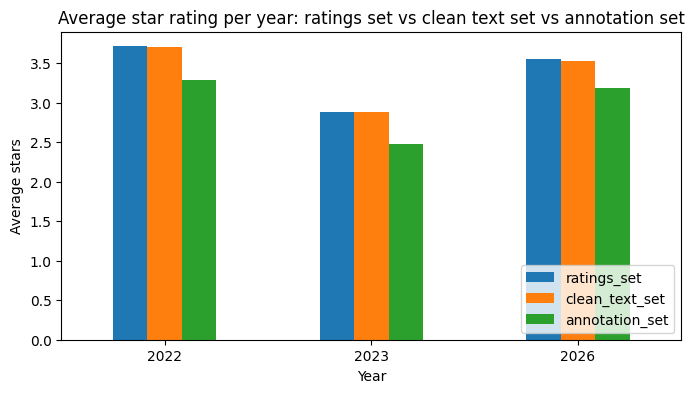

In [83]:
mean_rating_all.plot(kind='bar', figsize=(8, 4))
plt.title('Average star rating per year: ratings set vs clean text set vs annotation set')
plt.xlabel('Year')
plt.ylabel('Average stars')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

In [84]:
star_pct_all = pd.DataFrame({
    'ratings_set': df_ratings['score'].value_counts(normalize=True),
    'clean_text_set': df_clean_full['score'].value_counts(normalize=True),
    'annotation_set': df_annotate['score'].value_counts(normalize=True)}).sort_index().mul(100).round(1)
star_pct_all

,ratings_set,clean_text_set,annotation_set
score,,,
1,32.0,32.1,40.8
2,4.2,4.3,5.7
3,5.3,5.4,6.6
4,8.3,8.4,8.5
5,50.2,49.8,38.4


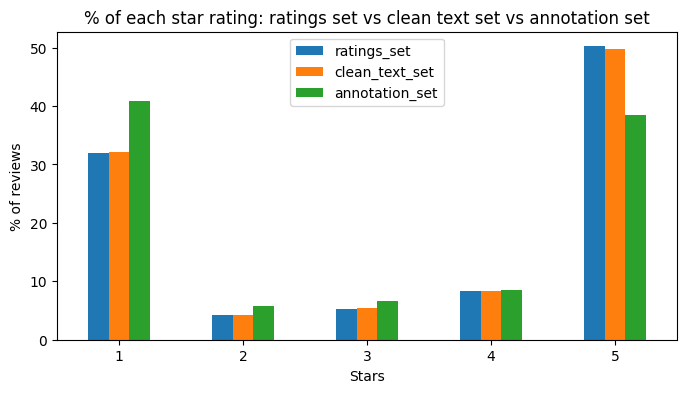

In [85]:
star_pct_all.plot(kind='bar', figsize=(8, 4))
plt.title('% of each star rating: ratings set vs clean text set vs annotation set')
plt.xlabel('Stars')
plt.ylabel('% of reviews')
plt.xticks(rotation=0)
plt.show()

In [86]:
star_counts_all = pd.concat({
    'ratings_set': pd.crosstab(df_ratings['year'], df_ratings['score']).stack(),
    'clean_text_set': pd.crosstab(df_clean_full['year'], df_clean_full['score']).stack(),
    'annotation_set': pd.crosstab(df_annotate['year'], df_annotate['score']).stack()}, axis=1)
star_counts_all

ratings_set  clean_text_set  annotation_set
year score                                             
2022 1            32579           30280           25833
     2             5652            5400            4780
     3             7821            7427            6006
     4            12829           12136            8120
     5            77329           71062           35464
2023 1            42040           38799           33155
     2             4029            3818            3402
     3             4341            4095            3399
     4             6296            5871            4072
     5            35541           32589           16923
2026 1            12559           12160           11132
     2             1841            1805            1679
     3             2229            2174            1851
     4             3419            3279            2325
     5            23877           22522           13647

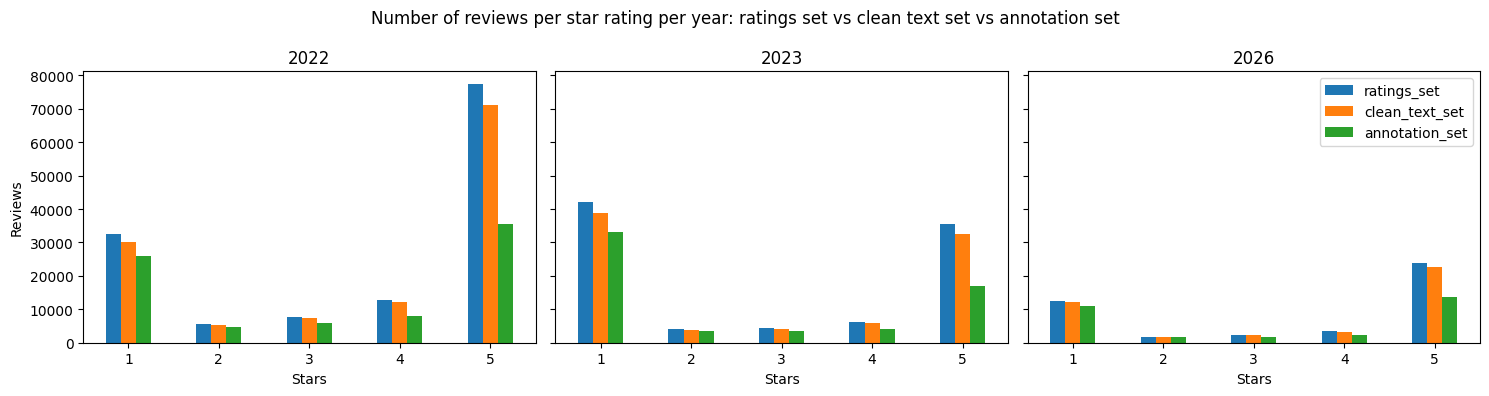

In [87]:
years = star_counts_all.index.get_level_values('year').unique()
fig, axes = plt.subplots(1, len(years), figsize=(15, 4), sharey=True)

for ax, year in zip(axes, years):
    star_counts_all.loc[year].plot(kind='bar', ax=ax, legend=False)
    ax.set_title(str(year))
    ax.set_xlabel('Stars')
    ax.tick_params(axis='x', rotation=0)

axes[0].set_ylabel('Reviews')
axes[-1].legend()
fig.suptitle('Number of reviews per star rating per year: ratings set vs clean text set vs annotation set')
plt.tight_layout()
plt.show()